# Movimientos acotados en parpadeo: ¿pueden los cuadros de un movimiento mantener brillante cada trampa en movimiento?

**Pregunta:** ¿Pueden calcularse los hologramas intermedios de un movimiento de modo que cada trampa en movimiento se mantenga brillante, y vale la respuesta para los movimientos largos de un ordenamiento real?

- Nivel: 4, más allá del estado del arte (afirmación BS-2).
- Requisitos previos: `07-feedback-and-dynamics/04-moving-atoms-by-linear-phase-interpolation`, que construye la secuencia de interpolación lineal de fase con la que compara este notebook.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en cerca de dos minutos.

## Objetivos

El notebook anterior terminó con un número que LPI no puede cambiar por sí solo: entre dos de sus cuadros una trampa en movimiento puede bajar a menos de la mitad de su media, porque LPI interpola dos hologramas extremos y nunca optimiza lo que queda entre ellos. Un átomo retenido en esa trampa durante el instante tenue puede perderse. B2 hace otra pregunta sobre el mismo movimiento: si cada cuadro se optimiza mientras las fases de las trampas siguen un camino suave del inicio al final, ¿puede mantenerse el instante más tenue de cada trampa en movimiento en 0,9 de su media, y cómo tiene que ser el camino de las fases para eso? Al final podrás:

- decir qué queda fijo en B2 y qué queda libre, y cómo se mueven las posiciones y las fases;
- evaluar dos secuencias distintas con el mismo modelo transitorio;
- medir en la tarea de aceptación de B2 cuánto cae cada secuencia, en tres semillas;
- probar la afirmación en un problema más difícil, los movimientos largos del ordenamiento del caso C10, con el número de cuadros por defecto y con el que el movimiento necesita, y decir qué falla entonces;
- decir qué supone el modelo transitorio.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from dataclasses import replace
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.cases.library import random_loading
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import TrapSet, square_grid
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b2_flicker_bounded
from pipeline.model.holo.methods.beyond.b2_flicker_bounded import transient_min_ratio, trajectory
from pipeline.model.holo.methods.control import m16_rearrangement

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook toma el montaje óptico del caso C10 de `data/examples/cases.json` (256 x 256 píxeles, un bin focal de cerca de 0,5 micrómetros) y construye sobre él la tarea de aceptación de B2. El último paso usa el ordenamiento del propio C10, con su carga y su bloque objetivo.

- Propietario: este repositorio; el caso y la tarea son sintéticos.
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C10.

In [2]:
# el caso C10 aporta el montaje óptico y, para el último paso, el ordenamiento de 36 objetivos con 52 átomos
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C10"]
setup = build.setup_of(rec)
bin_m = focal_bin_m(setup)
print(rec["case_id"], "| bin focal", round(bin_m * 1e6, 3), "um | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")

C10_rearrangement | bin focal 0.498 um | SLM 256 x 256 píxeles


## Método

### Cuadros continuos en fase

B2 calcula $S + 1$ cuadros. Las posiciones de las trampas siguen el perfil de mínima sacudida $x_m(s) = x_m(0) + (x_m(S) - x_m(0))\,(10\tau^3 - 15\tau^4 + 6\tau^5)$ con $\tau = s/S$, que parte y termina con velocidad y aceleración cero. Las fases ópticas de las trampas siguen el mismo perfil, $\theta_m(s) = \theta_m(0) + \mathrm{wrap}(\theta_m^\text{fin} - \theta_m(0))\,h(\tau)$, y por defecto se retienen, $\theta^\text{fin} = \theta(0)$. Cada cuadro es un GS ponderado de fase fija (Kim et al., 2019) en el que las amplitudes objetivo son $w_m a_m e^{i\theta_m(s)}$: los pesos $w_m$ se adaptan para que las trampas sean iguales, pero las fases son las de la trayectoria, no libres. El cuadro parte del holograma y de los pesos del cuadro anterior, y ejecuta 10 iteraciones. El método rechaza una secuencia en que la fase se mueve más de 0,3 rad por cuadro.

La intensidad transitoria es un modelo, no una medición. Entre los cuadros $s$ y $s+1$ el campo mostrado se toma como la mezcla $(1 - a)\,e^{i\phi_s} + a\,e^{i\phi_{s+1}}$, con $a$ de 0 a 1, mientras el cristal líquido se relaja, y cada trampa se lee en su posición $x_m(s + a)$. El puntaje de una trampa es su menor intensidad sobre $s$ y $a$ dividida por su media sobre los cuadros. El modelo es la lectura que el pipeline hace del artículo de LPI y está marcado como no verificado en el método; es la misma función para toda secuencia de abajo, así que una comparación con ella es justa aunque sus valores absolutos no lo sean. La primera celda construye la tarea de aceptación de B2: una red de 4 x 4 con espaciado de 8 bins focales cuyas dos columnas de la derecha se mueven 4 bins en x.

In [3]:
# la tarea de aceptación de B2: una red de 4 x 4 a 8 bins focales, las dos columnas de la derecha se mueven
# 4 bins en x
start = square_grid(4, 4, 8 * bin_m * 1e6)
dest = TrapSet(replace(t, x_m=t.x_m + (4 * bin_m if i % 4 >= 2 else 0.0)) for i, t in enumerate(start))
moving = np.array([d.x_m != s.x_m for s, d in zip(start, dest)])
print(f"{len(start)} trampas, {int(moving.sum())} de ellas se mueven {4} bins en x")
print("x de la primera fila, desde y hasta (bins):",
      np.round(start.x_m[:4] / bin_m, 1), np.round(dest.x_m[:4] / bin_m, 1))

16 trampas, 8 de ellas se mueven 4 bins en x
x de la primera fila, desde y hasta (bins): [-12.  -4.   4.  12.] [-12.  -4.   8.  16.]


## Estado del arte

El estado del arte es LPI (la receta de arXiv 2501.01391, implementada en M16): dos hologramas WGS de fase fija, uno para el inicio y otro para el final, la posición, la amplitud y la fase de cada trampa leídas de ellos e interpoladas linealmente, y la transformada inversa en cada paso. La celda lo ejecuta con 12 pasos (13 cuadros, el tamaño del ordenamiento que hace el artículo) para tres semillas, y evalúa los cuadros con el modelo transitorio de B2, con las posiciones que usa LPI, que son lineales en el paso.

In [4]:
# LPI de M16 en 12 pasos, tres semillas; toda secuencia se evalúa con el modelo transitorio de B2, con
# posiciones lineales
lpi = {}
n_frames = {}
for seed in (1, 2, 3):
    run = m16_rearrangement.run(setup, Target.from_traps(dest), budget=Budget(30), rng=Rng(seed), atoms=start,
                                alpha=1.5, max_step_bins=4 / 12)
    order = run.meta["assignment"]
    origin = TrapSet(replace(t, x_m=start.x_m[order[i]], y_m=start.y_m[order[i]]) for i, t in enumerate(dest))
    along = trajectory(origin, dest, len(run.meta["frames"]), profile=lambda tau: tau)
    n_frames[seed] = len(run.meta["frames"])
    lpi[seed] = transient_min_ratio(setup, list(run.meta["frames"]), along)[moving]
for seed, ratio in lpi.items():
    print(f"semilla {seed}: {n_frames[seed]} cuadros | "
          f"menor intensidad transitoria de una trampa en movimiento "
          f"{ratio.min():.3f} | mediana {np.median(ratio):.3f}")

semilla 1: 13 cuadros | menor intensidad transitoria de una trampa en movimiento 0.669 | mediana 0.846
semilla 2: 13 cuadros | menor intensidad transitoria de una trampa en movimiento 0.700 | mediana 0.753
semilla 3: 13 cuadros | menor intensidad transitoria de una trampa en movimiento 0.642 | mediana 0.807


LPI mantiene la trampa en movimiento mediana en 0,846, 0,753 y 0,807 de su media, pero la peor trampa de cada semilla cae a 0,669, 0,700 y 0,642. Dos de las tres quedan bajo el 0,7 que el artículo informa para sus trampas en movimiento y la tercera queda sobre esa línea, y ninguna está cerca de 0,9. Las caídas difieren por semilla porque los dos hologramas extremos son independientes: cada uno tiene sus propias fases libres de trampa, y la interpolación entre dos conjuntos de fases sin relación pasa por la interferencia que formen. La tabla no dice cómo le iría a un átomo en una caída de 0,64, ya que eso depende de la profundidad de la trampa, que el notebook no modela. B2 pone una meta en la caída misma: su escalera de métodos pide un mínimo de al menos 0,9.

## Más allá del estado del arte

### B2 en su tarea de aceptación (BS-2)

La brecha que aborda B2 es que LPI no optimiza los cuadros que crea, de modo que los hologramas intermedios son tan desiguales como los deja la interpolación. La afirmación es que ligar las fases de las trampas a una trayectoria suave y reoptimizar cada cuadro mantiene la menor intensidad transitoria de una trampa en movimiento en o sobre 0,9 de su media. La celda ejecuta B2 en la misma tarea, las mismas tres semillas y 13 cuadros, e imprime la menor intensidad, la mediana y la peor desviación estándar relativa de cualquier cuadro (una verificación de que la optimización de cada cuadro no ha cedido su uniformidad).

In [5]:
# B2 en la misma tarea: 13 cuadros, fases de las trampas ligadas a una trayectoria suave, cada cuadro un WGS
# de fase fija desde el anterior
b2_runs = {}
for seed in (1, 2, 3):
    b2_runs[seed] = b2_flicker_bounded.run(setup, Target.from_traps(start), budget=Budget(30), rng=Rng(seed),
                                           destination=dest)
for seed, res in b2_runs.items():
    ratio = res.meta["transient_ratio"][moving]
    worst_frame = max(h["rel_std"] for h in res.history)
    print(f"semilla {seed}: {res.meta['n_frames']} cuadros | menor intensidad transitoria "
          f"{ratio.min():.3f} | mediana {np.median(ratio):.3f} | peor dispersión de un cuadro {worst_frame:.2f} %")

semilla 1: 13 cuadros | menor intensidad transitoria 0.916 | mediana 0.925 | peor dispersión de un cuadro 0.36 %
semilla 2: 13 cuadros | menor intensidad transitoria 0.920 | mediana 0.932 | peor dispersión de un cuadro 0.14 %
semilla 3: 13 cuadros | menor intensidad transitoria 0.926 | mediana 0.934 | peor dispersión de un cuadro 0.39 %


La figura grafica, ordenada, la menor intensidad transitoria de cada una de las 24 trampas en movimiento (3 semillas por 8) para LPI y para B2, con las rectas en 0,7 y 0,9.

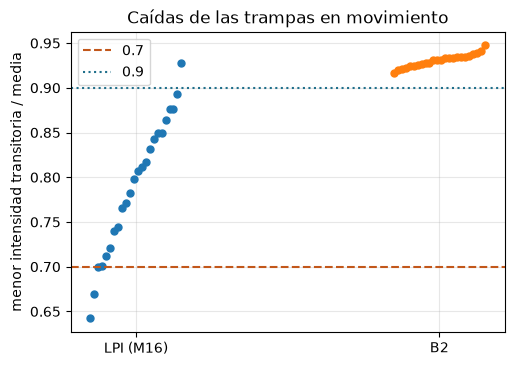

In [6]:
# menor intensidad transitoria de cada trampa en movimiento (3 semillas x 8 trampas), LPI frente a B2
pooled = {"LPI (M16)": np.concatenate(list(lpi.values())),
          "B2": np.concatenate([res.meta["transient_ratio"][moving] for res in b2_runs.values()])}
fig, ax = plt.subplots(figsize=(5.6, 3.9))
for k, (name, values) in enumerate(pooled.items()):
    ax.plot(np.full(values.size, k) + np.linspace(-0.15, 0.15, values.size), np.sort(values), "o", markersize=5)
ax.axhline(0.7, color="#c2571a", linestyle="--", label="0.7")
ax.axhline(0.9, color="#1f6f8b", linestyle=":", label="0.9")
ax.set_xticks([0, 1])
ax.set_xticklabels(list(pooled))
ax.set_ylabel("menor intensidad transitoria / media")
ax.set_title("Caídas de las trampas en movimiento")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

B2 llega a 0,916, 0,920 y 0,926 para la menor trampa en movimiento en las tres semillas, con medianas de 0,925 a 0,934: toda la columna de B2 queda sobre la línea de 0,9, en una banda estrecha hasta cerca de 0,95, donde los puntos de LPI van de 0,64 a 0,93, dos quedan bajo 0,7 y solo uno llega a 0,9. Los cuadros individuales se mantienen uniformes, con una peor desviación estándar relativa de 0,14 a 0,39 por ciento, de modo que la ganancia no se paga con la calidad de los hologramas. El criterio de aceptación se cumple en las tres semillas, y B2 queda sobre LPI en cada una. La figura es para una tarea, en la que las trampas se mueven media separación de la red, y para el modelo transitorio del pipeline; no dice que el mismo margen se mantenga para un movimiento más largo, que es lo que prueba el paso siguiente.

### Un problema más largo: el ordenamiento del caso C10

La tarea de aceptación mueve cada trampa 4 bins. El ordenamiento de C10 mueve átomos hasta 29 bins, muchas trampas a la vez, en un campo donde las demás se mantienen. La celda deja que M16 planifique el ordenamiento con la asignación húngara con el exponente 1,0 (el plan sin caminos cruzados del notebook anterior) y construye los cuadros de LPI, y luego toma la asignación propia de M16 como el único plan de todos los brazos de abajo: las posiciones inicial y final de cada trampa, y las trampas que se mueven. Imprime cuántas trampas se mueven y el movimiento más largo.

In [7]:
# el ordenamiento del caso C10 (52 átomos a 36 objetivos, alpha = 1.0) tal como lo planifica M16: un plan para
# todos los brazos de abajo
sites = {t["id"]: t for t in rec["target"]["traps"]}
loaded, wanted = random_loading(rec), rec["rearrangement"]["target_ids"]
atoms = build.trapset_of([sites[i] for i in loaded])
goal = build.trapset_of([sites[i] for i in wanted])
lpi10 = m16_rearrangement.run(setup, Target.from_traps(goal), budget=Budget(30), rng=Rng(1), atoms=atoms,
                              alpha=1.0, max_step_bins=1.25)
pick = lpi10.meta["assignment"]
origin10 = TrapSet(replace(t, x_m=atoms.x_m[pick[i]], y_m=atoms.y_m[pick[i]]) for i, t in enumerate(goal))
moving10 = np.array([np.hypot(a.x_m - g.x_m, a.y_m - g.y_m) > 0 for a, g in zip(origin10, goal)])
longest = max(np.hypot(a.x_m - g.x_m, a.y_m - g.y_m) for a, g in zip(origin10, goal)) / bin_m
print(f"{len(goal)} trampas, {int(moving10.sum())} en movimiento, movimiento más largo {longest:.1f} bins")
print(f"las mismas trampas en movimiento que las de M16: {bool(np.array_equal(moving10, lpi10.meta['moved']))}")


36 trampas, 16 en movimiento, movimiento más largo 29.0 bins
las mismas trampas en movimiento que las de M16: True


Se mueven dieciséis trampas, la más lejana 29,0 bins, las mismas que mueve M16. B2 tal como está retiene las fases de las trampas del inicio durante todo el movimiento, y al final de un movimiento largo las fases que hacen iguales a las trampas son otras. La celda prueba por eso cinco secuencias sobre el plan de arriba. Con 25 cuadros: LPI con 24 pasos, B2 con las fases retenidas, y B2 con las fases interpoladas hacia las del holograma final (`end_phases`, el mismo holograma final que usa LPI), para el cual el límite de 0,3 rad por cuadro se relaja a 1,0 rad. Con el número de cuadros que `frames_for_move` da para este ordenamiento, un paso máximo de 0,2 unidades de Fourier por cuadro: B2 con las fases finales, y LPI con tantos cuadros como él.

In [8]:
# cinco secuencias sobre un plan: LPI, B2 con las fases retenidas y B2 con las fases finales con 25 cuadros,
# y luego B2 con las fases finales y LPI con los cuadros del movimiento
along10 = trajectory(origin10, goal, len(lpi10.meta["frames"]), profile=lambda tau: tau)
ratio_lpi = transient_min_ratio(setup, list(lpi10.meta["frames"]), along10)[moving10]
held = b2_flicker_bounded.run(setup, Target.from_traps(origin10), budget=Budget(30), rng=Rng(1),
                              destination=goal, frames=25)
end = np.angle(m07_phase_fixed_wgs.run(setup, Target.from_traps(goal), budget=Budget(30), rng=Rng(1)).fields)
locked = b2_flicker_bounded.run(setup, Target.from_traps(origin10), budget=Budget(30), rng=Rng(1),
                                destination=goal, frames=25, end_phases=end, phase_velocity_max=1.0)
n_move = b2_flicker_bounded.frames_for_move(setup, origin10, goal)
long_b2 = b2_flicker_bounded.run(setup, Target.from_traps(origin10), budget=Budget(30), rng=Rng(1),
                                 destination=goal, frames=n_move, end_phases=end, phase_velocity_max=1.0)
long_lpi = m16_rearrangement.run(setup, Target.from_traps(goal), budget=Budget(30), rng=Rng(1), atoms=atoms,
                                 alpha=1.0, max_step_bins=longest / (n_move - 1))
along_long = trajectory(origin10, goal, len(long_lpi.meta["frames"]), profile=lambda tau: tau)
ratio_long_lpi = transient_min_ratio(setup, list(long_lpi.meta["frames"]), along_long)[moving10]
stress = {"LPI, 25 cuadros": ratio_lpi, "B2, fases retenidas": held.meta["transient_ratio"][moving10],
          "B2, fases finales": locked.meta["transient_ratio"][moving10],
          f"B2, {n_move} cuadros": long_b2.meta["transient_ratio"][moving10],
          f"LPI, {len(long_lpi.meta['frames'])} cuadros": ratio_long_lpi}
for name, ratio in stress.items():
    print(f"{name:22s} menor {ratio.min():.3f} | mediana {np.median(ratio):.3f} | "
          f"fracción de trampas en movimiento en o sobre 0.7 {np.mean(ratio >= 0.7):.3f}")


LPI, 25 cuadros        menor 0.646 | mediana 0.764 | fracción de trampas en movimiento en o sobre 0.7 0.812
B2, fases retenidas    menor 0.177 | mediana 0.540 | fracción de trampas en movimiento en o sobre 0.7 0.250
B2, fases finales      menor 0.333 | mediana 0.714 | fracción de trampas en movimiento en o sobre 0.7 0.562
B2, 137 cuadros        menor 0.909 | mediana 0.927 | fracción de trampas en movimiento en o sobre 0.7 1.000
LPI, 137 cuadros       menor 0.725 | mediana 0.843 | fracción de trampas en movimiento en o sobre 0.7 1.000


La figura pone las cinco secuencias lado a lado: la menor intensidad y la mediana de las trampas en movimiento a la izquierda, con la recta de 0,7, y la fracción de trampas en o sobre 0,7 a la derecha.

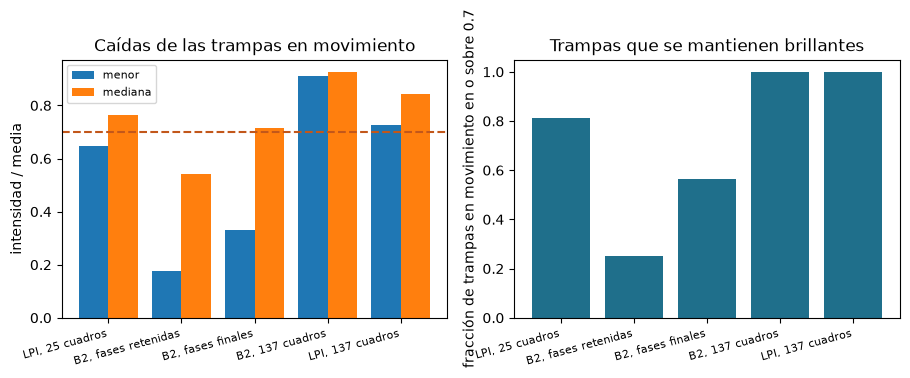

In [9]:
# las cinco secuencias del ordenamiento largo: menor intensidad y mediana de las trampas en movimiento, y
# fracción en o sobre 0.7
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.6))
slots = np.arange(len(stress))
a.bar(slots - 0.2, [r.min() for r in stress.values()], 0.4, label="menor")
a.bar(slots + 0.2, [np.median(r) for r in stress.values()], 0.4, label="mediana")
a.axhline(0.7, color="#c2571a", linestyle="--")
b.bar(slots, [np.mean(r >= 0.7) for r in stress.values()], color="#1f6f8b")
for ax in (a, b):
    ax.set_xticks(slots)
    ax.set_xticklabels(list(stress), rotation=15, ha="right", fontsize=8)
a.set_ylabel("intensidad / media")
b.set_ylabel("fracción de trampas en movimiento en o sobre 0.7")
a.legend(fontsize=8)
a.set_title("Caídas de las trampas en movimiento")
b.set_title("Trampas que se mantienen brillantes")
plt.tight_layout()
plt.show()

Con 25 cuadros la afirmación no se traslada, y LPI es la mejor secuencia. B2 con las fases retenidas colapsa, con una menor trampa en movimiento en 0,177, una mediana de 0,540 y un cuarto de las trampas en movimiento en o sobre 0,7: las fases del inicio no son las que hacen iguales a las trampas al final del movimiento. Darle a B2 las fases finales repara parte de esto, con una menor de 0,333, una mediana de 0,714 y 56,2 por ciento en o sobre 0,7, pero LPI va adelante en las tres medidas, con una menor de 0,646, una mediana de 0,764 y 81,2 por ciento en o sobre 0,7: con 25 cuadros el camino de fases finales de B2 mueve las fases demasiado rápido para que los cuadros lo sigan. Con los cuadros que el movimiento necesita, 137, el orden se invierte: B2 mantiene toda trampa en movimiento en o sobre 0,909 de su media, con una mediana de 0,927, lo que cumple el 0,9 de la afirmación, mientras LPI con tantos cuadros tiene una menor de 0,725 y una mediana de 0,843, con todas las trampas en o sobre 0,7 pero ninguna de sus peores cerca de 0,9. La comparación es de una carga y una semilla, con dos números de cuadros, y descansa en el modelo transitorio del pipeline.

## Resultados

**Respuesta:** Sí para los movimientos cortos de la tarea de aceptación, y para los movimientos largos de un ordenamiento completo solo con los cuadros que el movimiento necesita. En la tarea de aceptación, 8 de 16 trampas que se mueven 4 bins, B2 tiene una menor intensidad transitoria de 0,916, 0,920 y 0,926 de la media en tres semillas, sobre el 0,9 pedido, frente a 0,669, 0,700 y 0,642 de LPI bajo el mismo modelo transitorio, con cada cuadro de B2 uniforme hasta 0,39 por ciento o mejor. En el ordenamiento del caso C10, 16 trampas que se mueven hasta 29,0 bins en el plan propio de M16, 25 cuadros no bastan: B2 con las fases retenidas cae a una menor de 0,177, con las fases finales llega a una menor de 0,333 y una mediana de 0,714, y LPI va adelante en todas las medidas, con una menor de 0,646, una mediana de 0,764 y 81,2 por ciento de las trampas en movimiento en o sobre 0,7. Con los 137 cuadros que da `frames_for_move`, B2 con las fases finales mantiene toda trampa en movimiento en o sobre 0,909 de su media (una semilla aquí; 0,902 a 0,917 en cinco de seis semillas del registro), y LPI con tantos cuadros llega a 0,725.

Lo que el notebook no muestra es una medición en hardware de las caídas, más de una carga, ni la dependencia del número de cuadros más allá de los valores usados.

## Resumen

- B2 fija las fases de las trampas a una trayectoria suave y reoptimiza cada cuadro con WGS de fase fija; LPI interpola dos hologramas independientes y no optimiza nada entre ellos.
- Ambos se evalúan aquí con un modelo transitorio, que mezcla cuadros consecutivos y no está verificado en términos absolutos.
- En la tarea de aceptación B2 mantiene la menor trampa en movimiento en 0,916 a 0,926 de su media frente a 0,642 a 0,700 de LPI.
- En los movimientos largos de C10 las fases del inicio no pueden retenerse, y con 25 cuadros LPI supera a B2 con fases finales en todas las medidas; con los 137 cuadros que el movimiento necesita, B2 cumple 0,9 (0,909) y LPI no (0,725).
- En esta semilla la afirmación se sostiene cuando los cuadros siguen al movimiento. El registro del producto halla, en el plan propio de M16 de C10, 5 de 6 semillas en o sobre 0,9 con 137 cuadros (0,902 a 0,917, con una semilla que cae a 0,155 por su trayectoria de fase) y 6 de 8 en movimientos largos de la red, donde el límite es la trayectoria de fase que prescriben las fases finales, así que el número de cuadros es una condición, no todo el límite.

## Referencias

- Parallel assembly of neutral atom arrays with an SLM using linear phase interpolation. https://arxiv.org/abs/2501.01391
- Lee, Kim and Ahn (2017). Defect-free atomic array formation using the Hungarian matching algorithm. Physical Review A 95, 053424. https://doi.org/10.1103/PhysRevA.95.053424
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178